# 03. Eksperimen skenario A sampai D
Membaca hasil dari `results/` (dibuat oleh `src/run_experiments.py`, `src/analyze_results.py`, `src/measure_latency.py`). Untuk menjalankan ulang dari awal:
```
python src/run_experiments.py tuning   # lalu commit results/config_beku.json
python src/run_experiments.py final
python src/analyze_results.py
python src/measure_latency.py
```
Fase `final` menolak berjalan bila konfigurasi belum di-commit (aturan: test dibuka sekali).

In [1]:
import os, sys
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
sys.path.insert(0, 'src')
import json
import pandas as pd
pd.set_option('display.width', 160)
print('akar repositori:', Path.cwd().name)

akar repositori: ttki-phishing-detection


## Hasil utama pada data test (rata-rata lima seed)

In [2]:
pd.read_csv('results/tables/tabel2_hasil.csv')

,skenario,model,F1,Precision,Recall,ROC-AUC,False negative (rata-rata),n test (rata-rata)
0,A,LR,"0,9999 ± 0,0000","1,0000","0,9998","1,0000","3,2",35306
1,A,RF,"1,0000 ± 0,0000","1,0000","1,0000","1,0000","0,2",35306
2,B,LR,"0,9909 ± 0,0003","0,9953","0,9865","0,9941","202,8",35306
3,B,RF,"0,9944 ± 0,0005","0,9971","0,9916","0,9975","126,2",35306
4,C,LR,"0,9917 ± 0,0017","0,9956","0,9879","0,9945","183,2",35488
5,C,RF,"0,9921 ± 0,0062","0,9975","0,9868","0,9973","202,6",35488
6,D,LR,"0,9999 ± 0,0000","1,0000","0,9997","1,0000","4,2",35488
7,D,RF,"1,0000 ± 0,0000","1,0000","1,0000","1,0000","0,0",35488
8,R_acak,ATURAN,"0,9952 ± 0,0001","1,0000","0,9905","0,9953","142,8",35306
9,R_grup,ATURAN,"0,9949 ± 0,0015","1,0000","0,9898","0,9949","155,4",35488


## Selisih F1 dengan interval bootstrap 95% (per seed, diringkas)

In [3]:
a = pd.read_csv('results/analysis_selisih.csv')
a.groupby(['perbandingan','model']).agg(selisih=('selisih','mean'), sd=('selisih','std'), seed_ci_tanpa_nol=('mencakup_nol', lambda s: int((~s).sum()))).round(5)

selisih       sd  seed_ci_tanpa_nol
perbandingan                     model                                     
A-B: lengkap vs URL-only, acak   LR     0.00899  0.00028                  5
                                 RF     0.00564  0.00049                  5
A-D: acak vs grup, fitur lengkap LR     0.00003  0.00005                  0
                                 RF    -0.00001  0.00001                  0
B minus ATURAN (acak)            LR    -0.00434  0.00029                  5
                                 RF    -0.00089  0.00047                  1
B-C: acak vs grup, URL-only      LR    -0.00083  0.00153                  2
                                 RF     0.00225  0.00637                  3
C minus ATURAN (grup)            LR    -0.00312  0.00042                  5
                                 RF    -0.00275  0.00684                  1
D-C: lengkap vs URL-only, grup   LR     0.00813  0.00173                  5
                                 RF     0.00789  0.00623                  5

## Waktu inferensi

In [4]:
pd.read_csv('results/tables/tabel3_latensi.csv')

,Skenario (fitur),Model,Cakupan waktu,Median (ms),p95 (ms)
0,B (url_only),LR,ekstraksi + prediksi,"0,671","0,942"
1,A (semua),LR,prediksi saja (batas bawah),"0,632","1,009"
2,B (url_only),RF,ekstraksi + prediksi,"25,990","28,464"
3,A (semua),RF,prediksi saja (batas bawah),"26,222","28,776"
4,B (ekstraksi saja),-,ekstraksi 18 fitur dari string URL,"0,019","0,044"


## Gambar

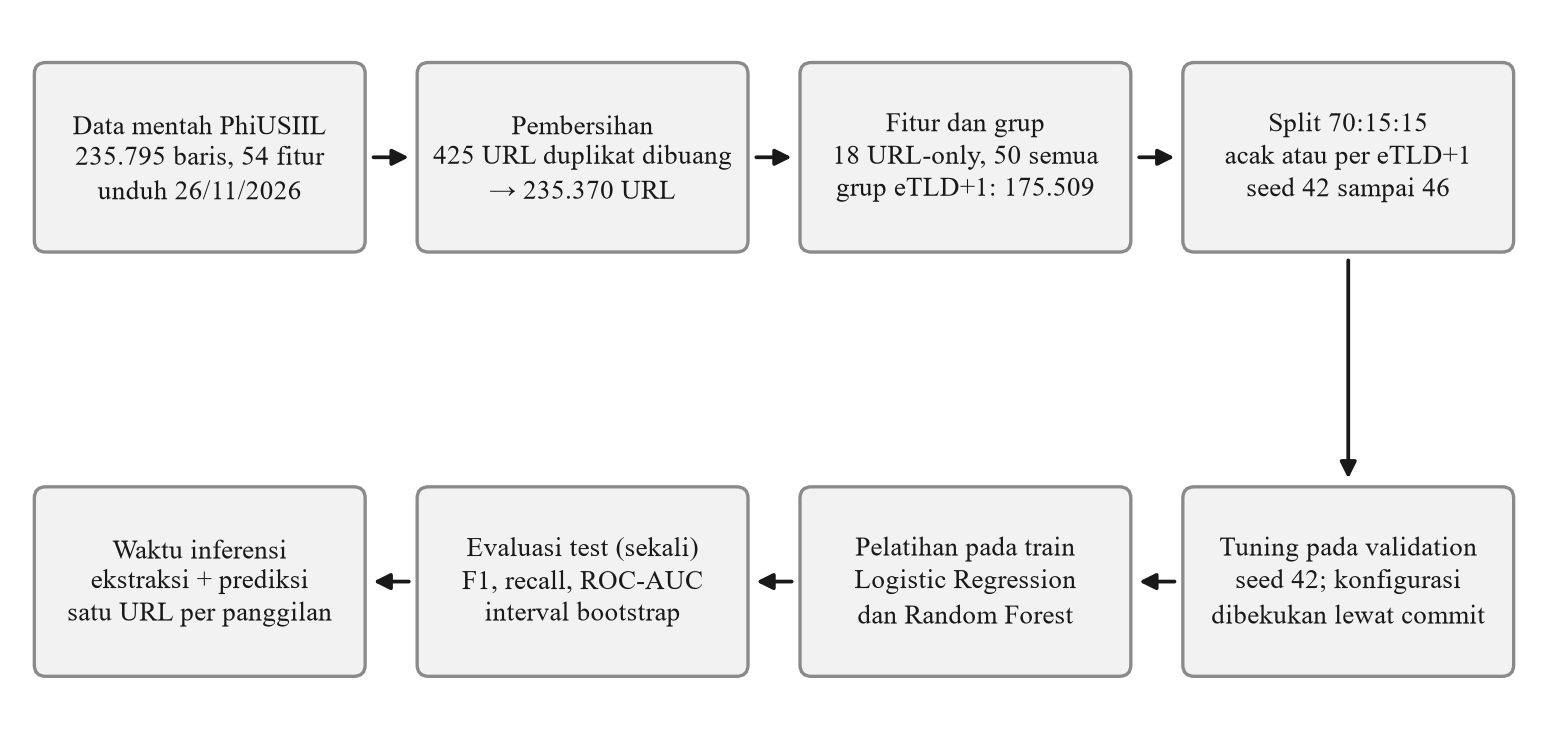

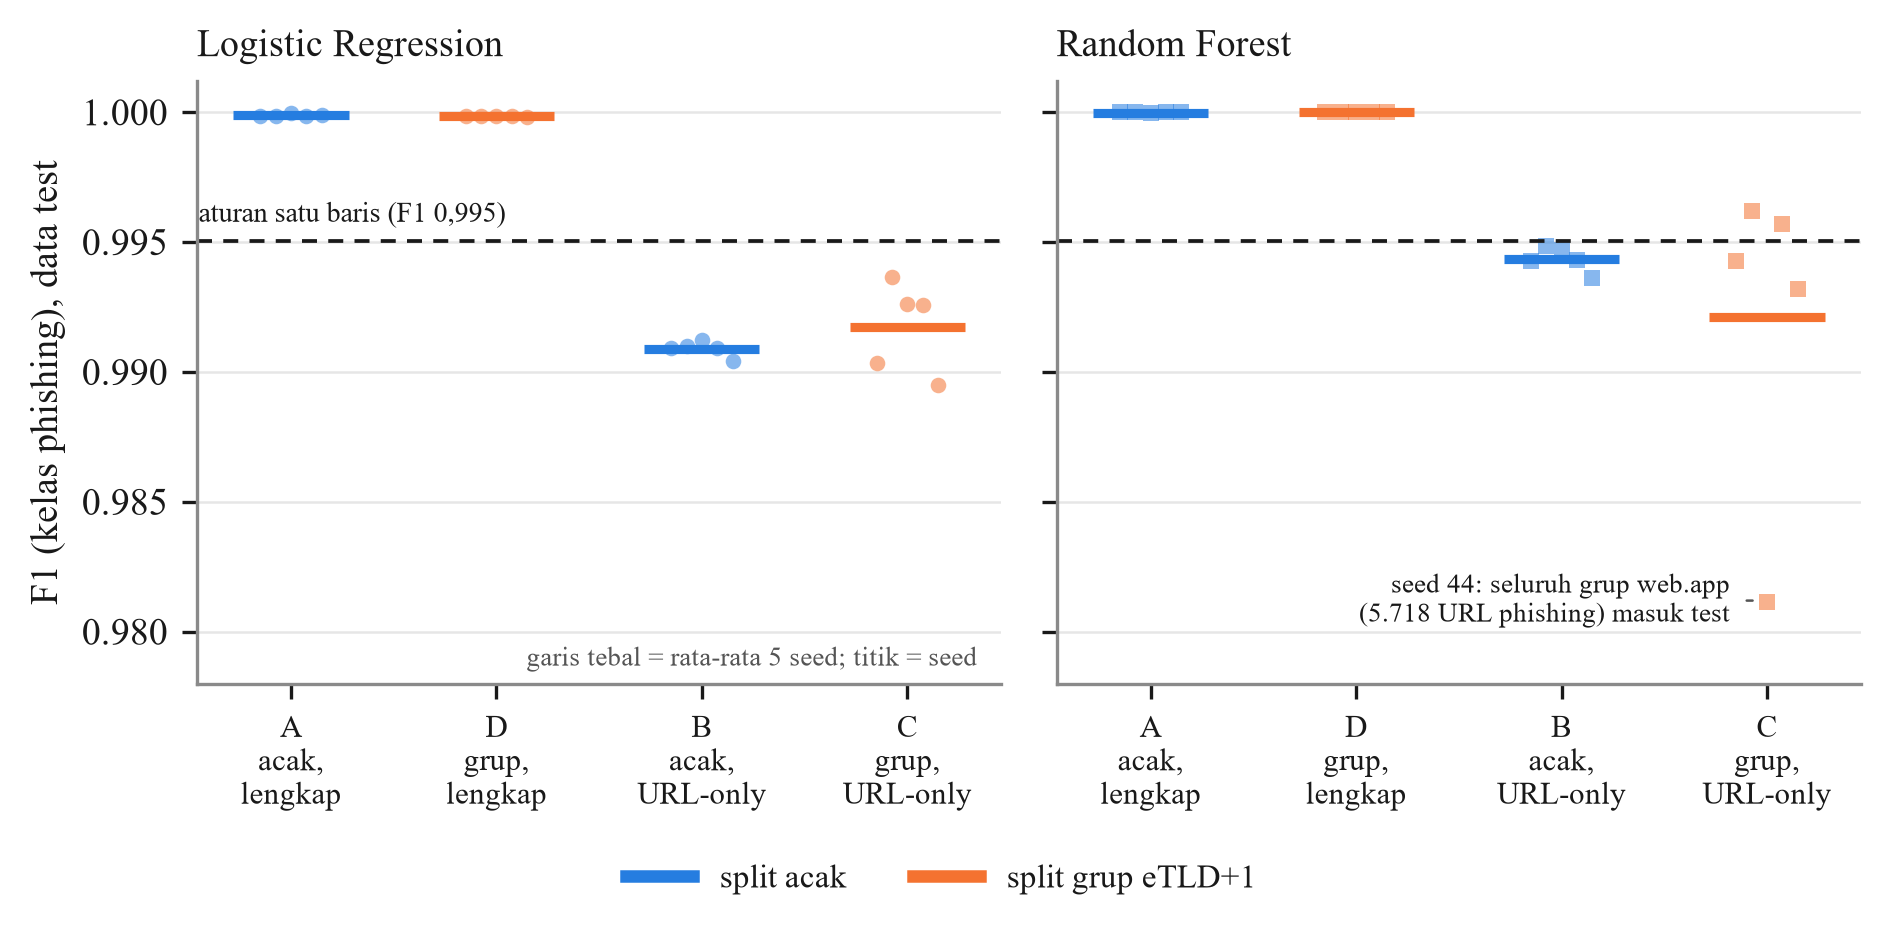

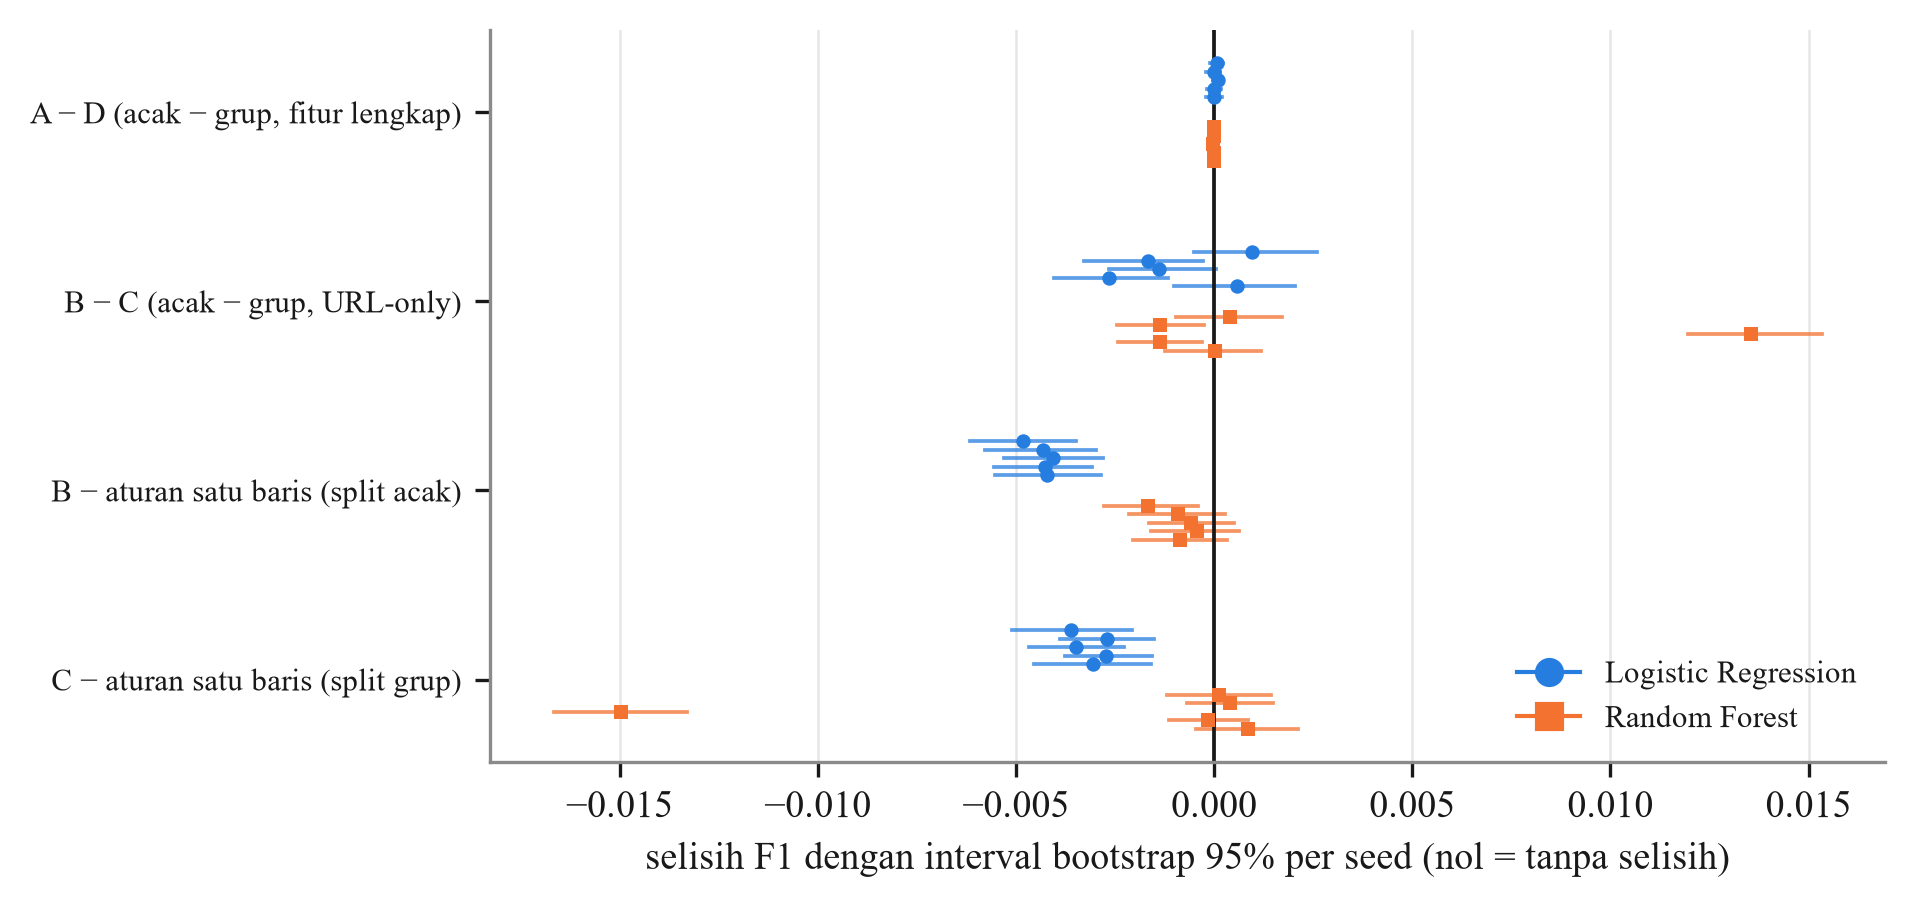

In [5]:
from IPython.display import Image, display
for f in ['gambar1_alur','gambar2_f1','gambar3_selisih']:
    display(Image(filename=f'figures/{f}.png', width=700))